In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

os.environ["LOKY_MAX_CPU_COUNT"] = "4"
os.environ["OMP_NUM_THREADS"] = "1"

In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

In [3]:
df = pd.read_csv("mall_customers.csv")

In [4]:
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,96,Male,32,60,47
1,16,Female,19,20,66
2,31,Male,40,15,84
3,159,Male,34,75,28
4,129,Male,43,86,13


In [5]:
df.tail()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
195,107,Male,18,48,46
196,15,Female,28,21,63
197,93,Male,36,67,22
198,180,Female,40,76,67
199,103,Male,34,67,40


In [6]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,35.035000,54.530000,49.235000
std,57.879185,10.142392,27.703547,28.860778
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.000000,27.000000,22.000000
50%,100.500000,35.000000,56.500000,47.500000
75%,150.250000,42.000000,81.000000,76.000000
max,200.000000,62.000000,105.000000,100.000000


In [7]:
df.shape

(200, 5)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [9]:
df.isnull().sum()

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(0)

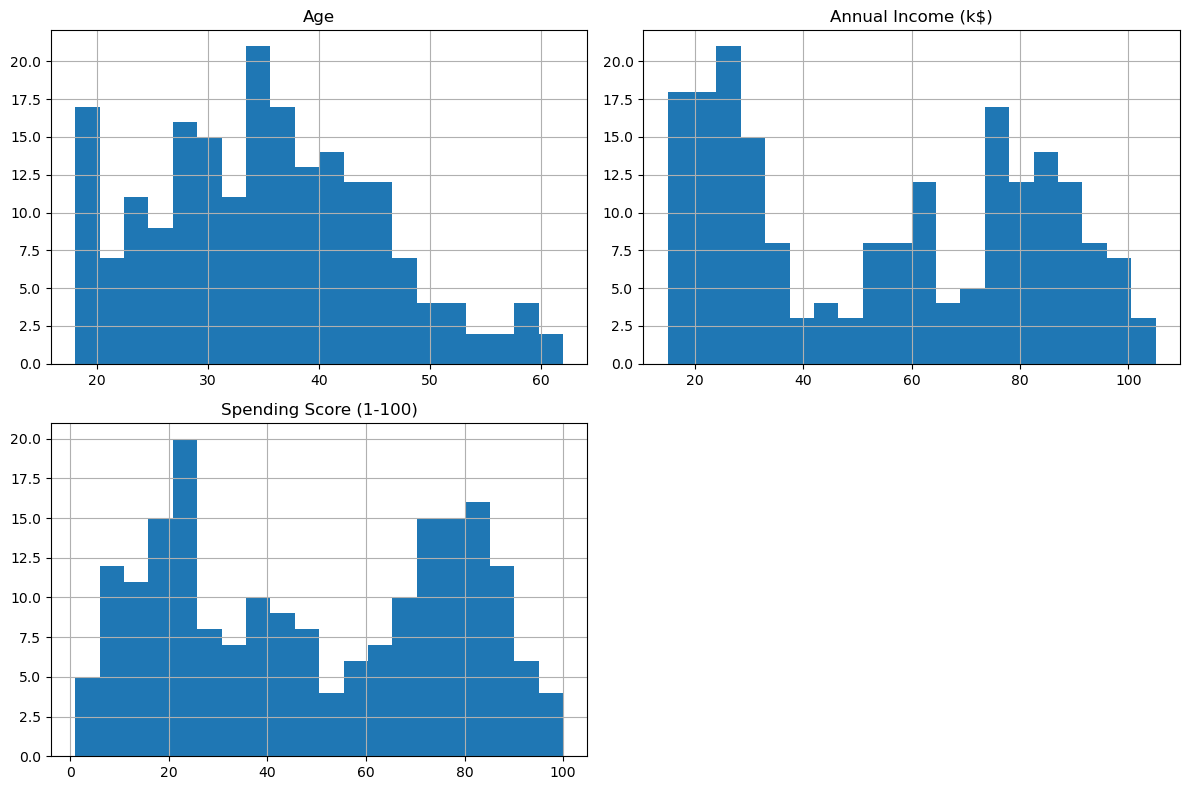

In [11]:
df[["Age", "Annual Income (k$)", "Spending Score (1-100)"]].hist(
    figsize=(12, 8),
    bins=20
)

plt.tight_layout()
plt.show()

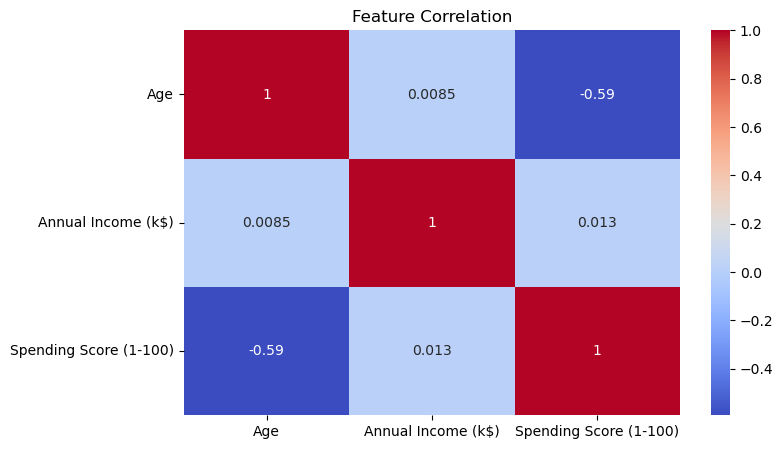

In [12]:
# Correlation Heatmap

plt.figure(figsize=(8, 5))

sns.heatmap(
    df[["Age", "Annual Income (k$)", "Spending Score (1-100)"]].corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Feature Correlation")
plt.show()

In [13]:
X = df[
    [
        "Age",
        "Annual Income (k$)",
        "Spending Score (1-100)"
    ]
]

In [14]:
X = X.fillna(X.median())

In [15]:
X.head()

,Age,Annual Income (k$),Spending Score (1-100)
0,32,60,47
1,19,20,66
2,40,15,84
3,34,75,28
4,43,86,13


In [16]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


In [17]:
X_scaled[:5]

array([[-0.29998999,  0.19794312, -0.07763507],
       [-1.58495535, -1.24953854,  0.58234987],
       [ 0.49075792, -1.43047375,  1.20759877],
       [-0.10230301,  0.74074874, -0.73762002],
       [ 0.78728839,  1.13880619, -1.25866076]])

In [18]:
#Elbow method
wcss = []

for k in range(1, 11):

    kmeans = KMeans(
        n_clusters=k,
        init="k-means++",
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    wcss.append(kmeans.inertia_)


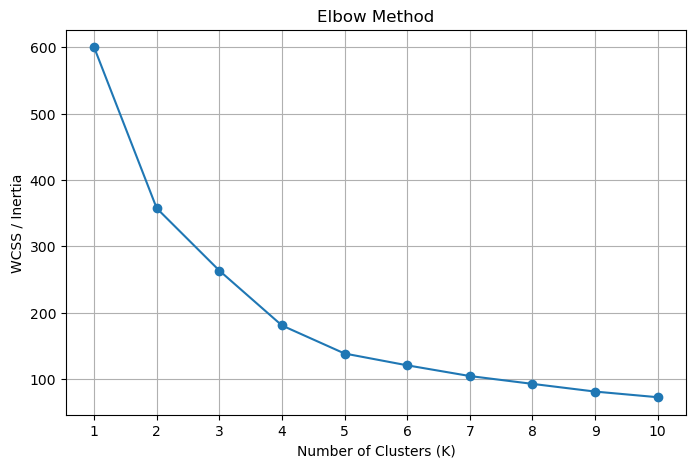

In [19]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 11),
    wcss,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS / Inertia")
plt.title("Elbow Method")

plt.xticks(range(1, 11))
plt.grid()
plt.show()


In [20]:
silhouette_scores = []

for k in range(2, 11):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)

    silhouette_scores.append(score)

    print(f"K = {k}, Silhouette Score = {score:.4f}")

K = 2, Silhouette Score = 0.3563
K = 3, Silhouette Score = 0.3628
K = 4, Silhouette Score = 0.4092
K = 5, Silhouette Score = 0.4281
K = 6, Silhouette Score = 0.4216
K = 7, Silhouette Score = 0.4126
K = 8, Silhouette Score = 0.3947
K = 9, Silhouette Score = 0.3830
K = 10, Silhouette Score = 0.3589


In [21]:
optimal_k = 5

kmeans = KMeans(
    n_clusters=optimal_k,
    init="k-means++",
    random_state=42,
    n_init=10
)


In [22]:
df["Cluster"] = kmeans.fit_predict(X_scaled)


print(df[["CustomerID", "Cluster"]].head(10))

   CustomerID  Cluster
0          96        0
1          16        1
2          31        1
3         159        0
4         129        4
5         116        0
6          70        3
7         171        2
8         175        2
9          46        3


In [23]:
final_score = silhouette_score(
    X_scaled,
    df["Cluster"]
)

print("\nFinal Silhouette Score:", round(final_score, 4))

print("\nCluster Distribution:")
print(df["Cluster"].value_counts().sort_index())



Final Silhouette Score: 0.4281

Cluster Distribution:
Cluster
0    41
1    41
2    40
3    41
4    37
Name: count, dtype: int64


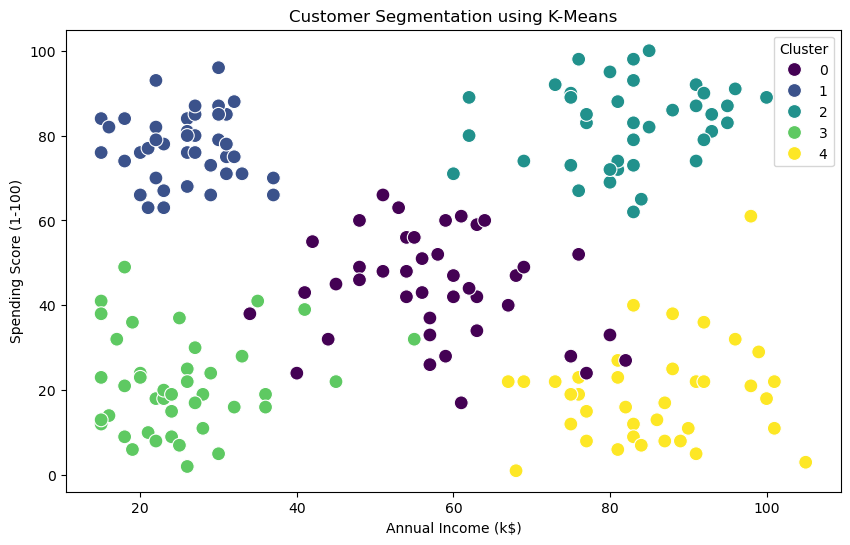

In [24]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Cluster",
    palette="viridis",
    s=100
)

plt.title("Customer Segmentation using K-Means")
plt.show()


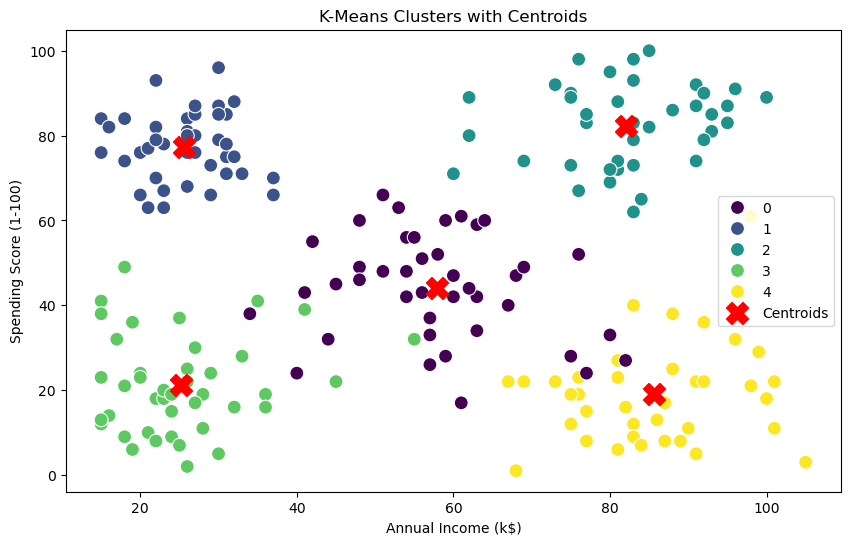

In [25]:
centroids = scaler.inverse_transform(kmeans.cluster_centers_)

centroid_df = pd.DataFrame(
    centroids,
    columns=X.columns
)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Cluster",
    palette="viridis",
    s=100
)

plt.scatter(
    centroid_df["Annual Income (k$)"],
    centroid_df["Spending Score (1-100)"],
    color="red",
    marker="X",
    s=250,
    label="Centroids"
)

plt.title("K-Means Clusters with Centroids")
plt.legend()
plt.show()


In [26]:
cluster_analysis = df.groupby("Cluster")[
    [
        "Age",
        "Annual Income (k$)",
        "Spending Score (1-100)"
    ]
].mean().round(2)

print("\nCluster Profile:")
print(cluster_analysis)



Cluster Profile:
           Age  Annual Income (k$)  Spending Score (1-100)
Cluster                                                   
0        30.85               57.85                   44.07
1        25.71               25.54                   77.37
2        31.48               82.10                   82.32
3        45.66               25.20                   21.22
4        42.08               85.68                   19.05


In [27]:
cluster_analysis["Customer Count"] = (
    df.groupby("Cluster").size()
)

print("\nDetailed Cluster Analysis:")
print(cluster_analysis)


Detailed Cluster Analysis:
           Age  Annual Income (k$)  Spending Score (1-100)  Customer Count
Cluster                                                                   
0        30.85               57.85                   44.07              41
1        25.71               25.54                   77.37              41
2        31.48               82.10                   82.32              40
3        45.66               25.20                   21.22              41
4        42.08               85.68                   19.05              37


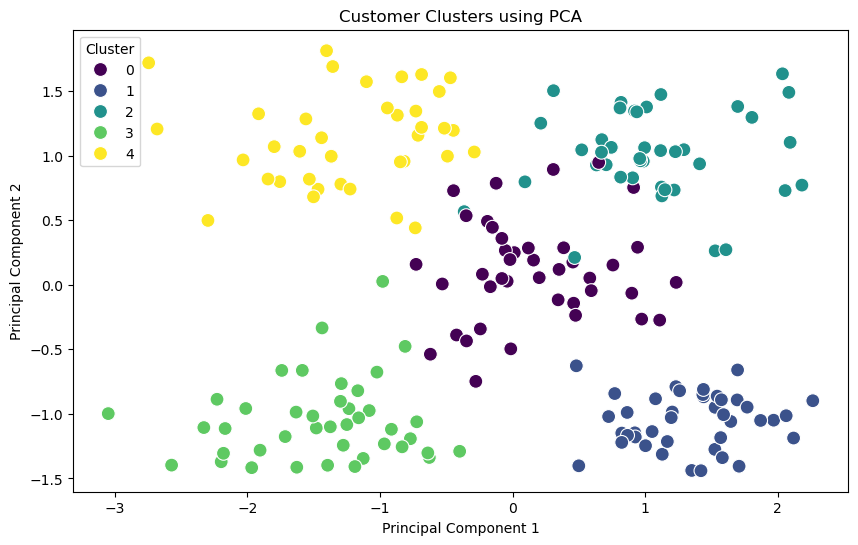


PCA Explained Variance: [0.53097636 0.33345536]


In [31]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=df["Cluster"],
    palette="viridis",
    s=100
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Customer Clusters using PCA")
plt.show()

print("\nPCA Explained Variance:",pca.explained_variance_ratio_)

In [32]:
new_customer = pd.DataFrame(
    [[25, 60, 75]],
    columns=X.columns
)

In [34]:
new_customer_scaled = scaler.transform(new_customer)



predicted_cluster = kmeans.predict(new_customer_scaled)

print("\nNew Customer belongs to Cluster:",predicted_cluster[0])


New Customer belongs to Cluster: 2


In [36]:
df.to_csv("Customer_Segmentation_Results.csv",index=False)

print("\nClustering completed successfully!")
print("Results saved to Customer_Segmentation_Results.csv")


Clustering completed successfully!
Results saved to Customer_Segmentation_Results.csv
